In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import os
import pandas as pd
from pathlib import Path

In [11]:
all_accs = {"type": [], "model": [],"accuracy": []}

for type in ["llms", "mlc"]:
    parent_dir = f"results_{type}"
    csv_paths = os.listdir(parent_dir)
    for path in csv_paths:
        df = pd.read_csv(Path(parent_dir) / path)
        for model in df.model.unique():
            acc = df[df.model==model]["correct"].mean()
            all_accs["type"].append(type)
            all_accs["model"].append(model)
            all_accs["accuracy"].append(acc)

In [12]:
df = pd.DataFrame(all_accs)
df

,type,model,accuracy
0,llms,mistralai/Mistral-Small-24B-Instruct-2501,0.299872
1,llms,openai/gpt-oss-120b,0.684079
2,llms,claude-sonnet-4-20250514,0.356098
3,llms,gemini-2.5-flash,0.443791
4,llms,meta-llama/Llama-3.3-70B-Instruct-Turbo,0.350963
5,llms,meta-llama/Llama-4-Scout-17B-16E-Instruct,0.293967
6,llms,openai/gpt-oss-20b,0.434040
7,llms,gpt-4.1,0.334275
8,llms,gpt-5.2,0.367394
9,llms,mistralai/Ministral-3-14B-Instruct-2512,0.246983


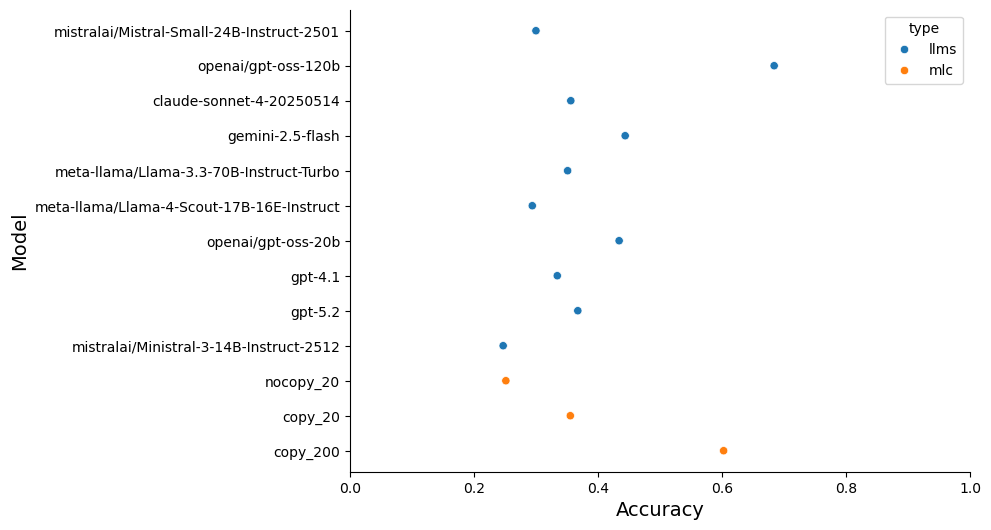

In [13]:
fig, ax = plt.subplots(figsize=(8,6))
sns.scatterplot(df, y="model", x="accuracy", hue="type", ax=ax)
ax.set_xlim((0,1))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_ylabel("Model", fontsize=14)
ax.set_xlabel("Accuracy", fontsize=14)
fig.savefig("figures/llm_mlc_comparison.png", bbox_inches="tight", dpi=300)
plt.show()

In [14]:
plt.savefig("figures/letstr_modelxacc.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>